# Báo cáo mô tả bộ dữ liệu tin đăng bất động sản

**Nguồn:** Tin đăng bất động sản trên Chợ Tốt, khu vực Thành phố Hồ Chí Minh  
**Quy mô thu thập:** 5 trang, tối đa 20 tin mỗi trang  
**Tệp dữ liệu:** `data_bds.csv`

Báo cáo này giới thiệu nội dung từng cột và tóm tắt các đặc điểm nổi bật của dữ liệu. Mỗi dòng là một tin đăng; dữ liệu gồm thông tin về giá, diện tích, địa điểm, loại hình và phần mô tả. Vì dữ liệu có thể trộn tin bán và tin cho thuê, các thống kê về giá cần được hiểu là mô tả các giá trị đã thu thập, không phải mức giá đại diện cho một loại giao dịch cụ thể.

## 1. Nhập các thư viện cần thiết

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 120

## 2. Tải và xem trước bộ dữ liệu

Tệp CSV nằm cùng thư mục với notebook. Hiển thị các dòng đầu để kiểm tra tên cột, định dạng và một số giá trị mẫu.

In [2]:
df = pd.read_csv("data_bds.csv")
display(df.head())

,title,price,area,district,region,category,body
0,Cho thuê gấp 2pn 2wc dt 76m2 giá tốt nhà đẹp,17500000,76.0000,Quận 7,Tp Hồ Chí Minh,Căn hộ/Chung cư,"Nội dung.\nĐịa chỉ căn hộ ở, 23, 25, 27, 33 đư..."
1,Cho thuê nhà nguyên căn đường Tân Kỳ Tân Quý 4...,9990000,60.0000,Quận Tân Phú,Tp Hồ Chí Minh,Nhà ở,Dự án: \nThông tin chi tiết: Cho thuê nhà nguy...
2,🎁FREE TIỀN THÁNG 10 - Chung cư mini full nt ba...,4500000,40.0000,Quận Gò Vấp,Tp Hồ Chí Minh,Phòng trọ,Dự án: \nThông tin chi tiết: 📍Địa chỉ: Dương Q...
3,khai Trương Căn Hộ Studio Ngay Ngã Năm Chuồng ...,4000000,30.0000,Quận Gò Vấp,Tp Hồ Chí Minh,Phòng trọ,Dự án: \nThông tin chi tiết: NGAY NGUYỄN OANH ...
4,"Cho thuê Nhà 382 Nguyễn chí thanh , 5,2x16m , ...",75000000,83.1999,Quận 10,Tp Hồ Chí Minh,"Văn phòng, Mặt bằng kinh doanh",Dự án: \nThông tin chi tiết: Cho thuê nhà 382 ...


### Bộ dữ liệu có những thông tin gì?

Mỗi dòng tương ứng với một tin đăng. Ý nghĩa các cột:

| Cột | Nội dung |
|---|---|
| `title` | Tiêu đề tin đăng bất động sản. |
| `price` | Giá được ghi trong tin; dữ liệu có thể gồm cả giá bán và giá thuê. |
| `area` | Diện tích được ghi trong tin, thường tính bằng mét vuông; cần kiểm tra nội dung từng tin khi giá trị bất thường. |
| `district` | Quận/huyện hoặc khu vực nhỏ hơn được API trả về. |
| `region` | Tỉnh/thành phố, trong bộ dữ liệu này là Thành phố Hồ Chí Minh. |
| `category` | Nhóm bất động sản, chẳng hạn căn hộ, nhà ở, phòng trọ hoặc đất. |
| `body` | Nội dung mô tả chi tiết do người đăng cung cấp. |

Như vậy, đây chủ yếu là dữ liệu tin đăng: `price` và `area` là thông tin số; các cột còn lại mô tả tiêu đề, địa điểm, loại hình và nội dung.

## 3. Thông tin tổng quan về bộ dữ liệu

Kiểm tra kích thước, tên cột, kiểu dữ liệu và số lượng giá trị không thiếu để nắm cấu trúc bảng.

In [3]:
print(f"Số dòng: {df.shape[0]}")
print(f"Số cột: {df.shape[1]}")
print("Tên cột:", df.columns.tolist())
print("\nKiểu dữ liệu:")
display(df.dtypes.to_frame(name="Kiểu dữ liệu"))
print("\nThông tin DataFrame:")
df.info()

Số dòng: 100
Số cột: 7
Tên cột: ['title', 'price', 'area', 'district', 'region', 'category', 'body']

Kiểu dữ liệu:


,Kiểu dữ liệu
title,str
price,int64
area,float64
district,str
region,str
category,str
body,str



Thông tin DataFrame:
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   title     100 non-null    str    
 1   price     100 non-null    int64  
 2   area      100 non-null    float64
 3   district  100 non-null    str    
 4   region    100 non-null    str    
 5   category  100 non-null    str    
 6   body      100 non-null    str    
dtypes: float64(1), int64(1), str(5)
memory usage: 5.6 KB


## 4. Thống kê mô tả các biến số

Dùng `describe()` để xem số lượng quan sát, trung bình, độ lệch chuẩn, các tứ phân vị, giá trị nhỏ nhất và lớn nhất của biến số. Trung vị được thể hiện ở hàng 50%.

In [4]:
numeric_columns = df.select_dtypes(include=np.number).columns
display(df[numeric_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
price,100.0,2.348500e+09,6.237021e+09,1200000.0,4275000.0,12500000.0,2.745000e+09,4.650000e+10
area,100.0,1.480930e+02,4.748638e+02,12.0,30.0,56.0,8.000000e+01,3.500000e+03


## 5. Kiểm tra dữ liệu thiếu và giá trị bất thường

Kiểm tra giá trị thiếu, các dòng trùng hoàn toàn và các điểm nằm ngoài khoảng $[Q1-1.5\times IQR,\ Q3+1.5\times IQR]$. Quy tắc IQR chỉ đánh dấu điểm cần kiểm tra thêm, không khẳng định đó là lỗi. Biểu đồ dùng trục log để dễ quan sát dữ liệu giá và diện tích có độ phân tán lớn; bảng thống kê ở phần trước vẫn giữ đơn vị và thang đo ban đầu.

In [5]:
print("Giá trị thiếu theo cột:")
display(df.isnull().sum().to_frame(name="Số giá trị thiếu"))
print(f"Số dòng trùng hoàn toàn: {df.duplicated().sum()}")

outlier_summary = []
for column in numeric_columns:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    count = ((df[column] < lower_bound) | (df[column] > upper_bound)).sum()
    outlier_summary.append({"Biến": column, "Cận dưới": lower_bound, "Cận trên": upper_bound, "Số điểm bị đánh dấu": count})

display(pd.DataFrame(outlier_summary))

Giá trị thiếu theo cột:


,Số giá trị thiếu
title,0
price,0
area,0
district,0
region,0
category,0
body,0


Số dòng trùng hoàn toàn: 7


,Biến,Cận dưới,Cận trên,Số điểm bị đánh dấu
0,price,-4.106812e+09,6.856088e+09,11
1,area,-4.500000e+01,1.550000e+02,12


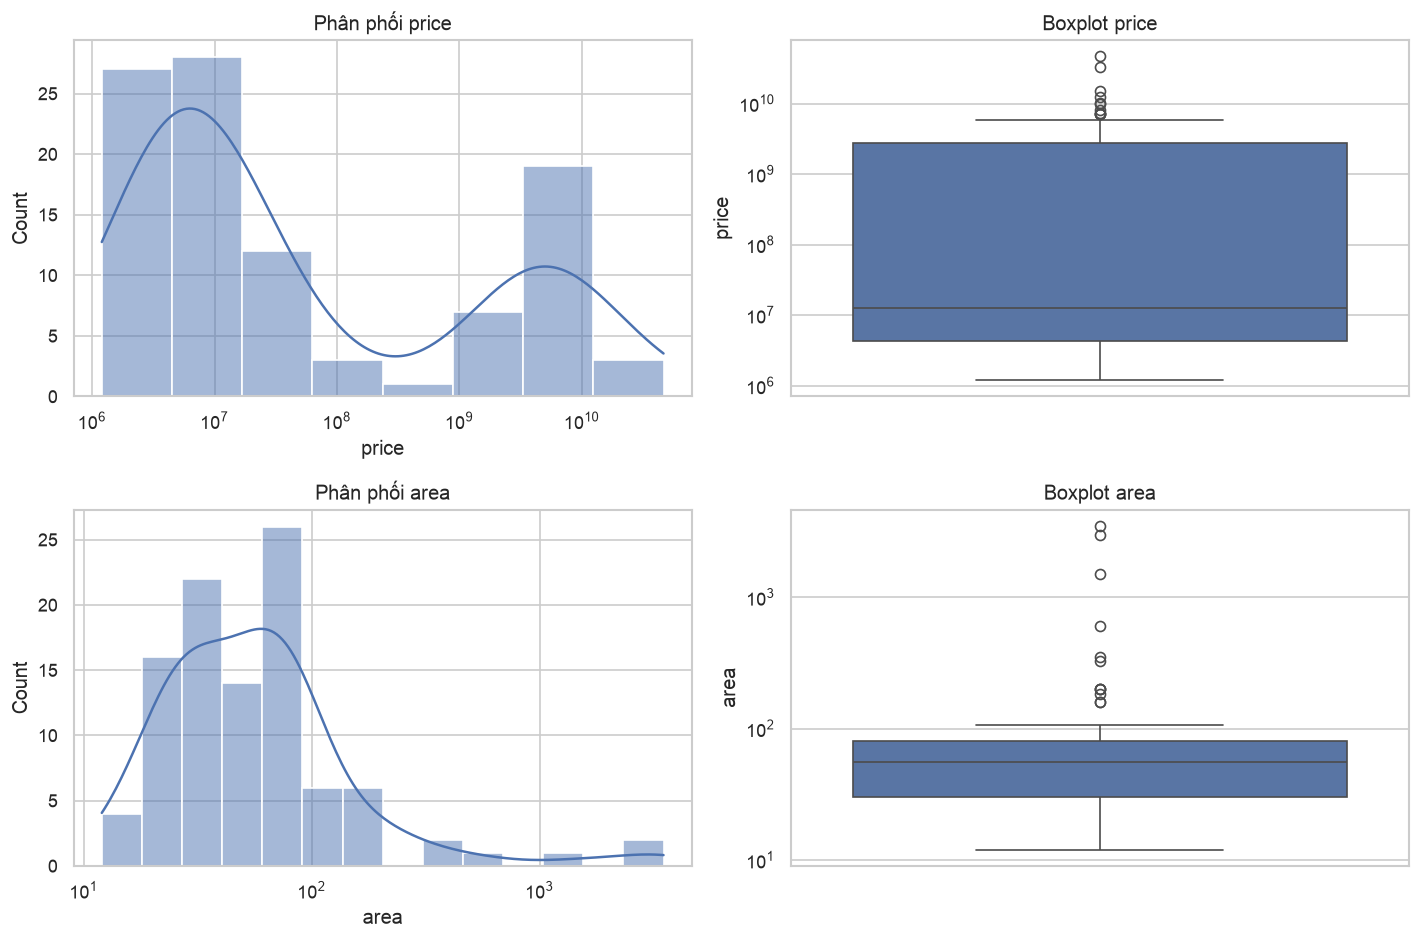

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for column, row in zip(numeric_columns, range(len(numeric_columns))):
    sns.histplot(data=df, x=column, ax=axes[row, 0], kde=True, log_scale=True)
    axes[row, 0].set_title(f"Phân phối {column}")
    sns.boxplot(data=df, y=column, ax=axes[row, 1])
    axes[row, 1].set_yscale("log")
    axes[row, 1].set_title(f"Boxplot {column}")
plt.tight_layout()
plt.show()

### Phân bố theo loại hình và khu vực

Bảng dưới đây cho biết số tin theo loại hình và một số quận/huyện có nhiều tin nhất.

In [7]:
print("Số tin theo loại hình:")
display(df["category"].value_counts().to_frame(name="Số tin"))
print("10 quận/huyện có nhiều tin nhất:")
display(df["district"].value_counts().head(10).to_frame(name="Số tin"))

Số tin theo loại hình:


,Số tin
category,
Căn hộ/Chung cư,32
Nhà ở,30
Phòng trọ,26
Đất,7
"Văn phòng, Mặt bằng kinh doanh",5


10 quận/huyện có nhiều tin nhất:


,Số tin
district,
Quận Bình Tân,15
Quận 7,12
Quận 12,11
Quận Tân Phú,9
Quận Bình Thạnh,9
Quận Gò Vấp,8
Thành phố Thủ Đức,7
Quận Tân Bình,6
Quận 10,4


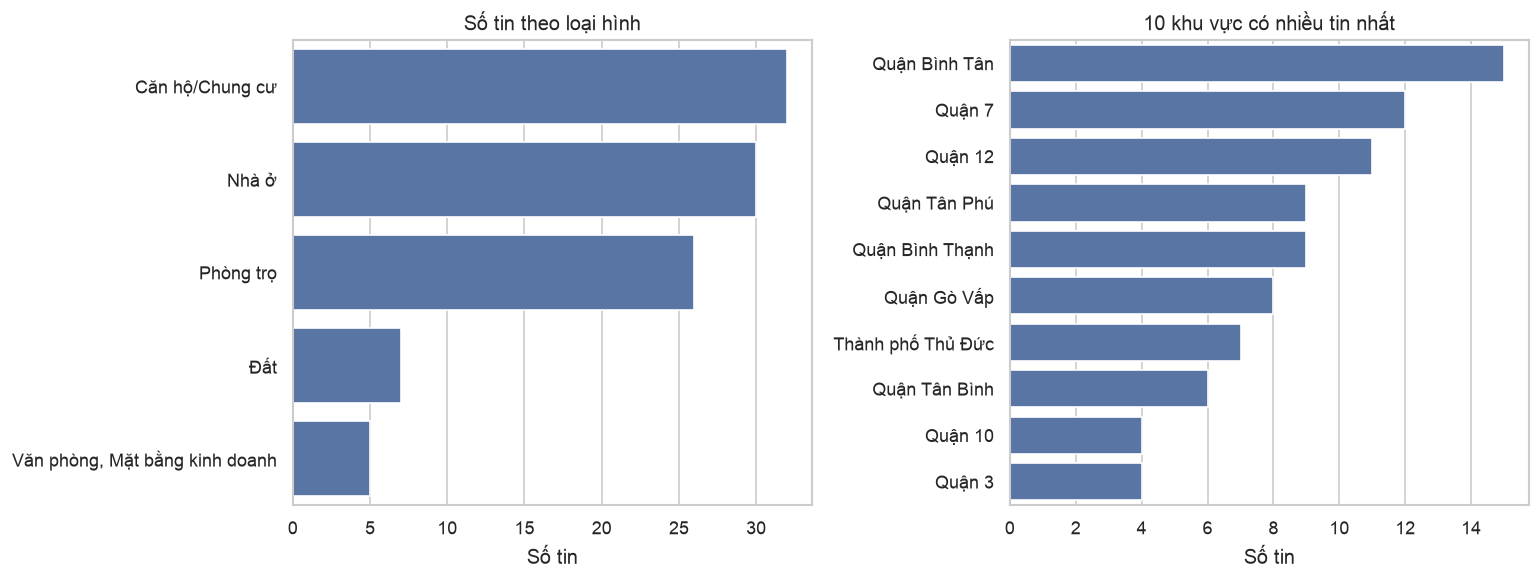

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
category_counts = df["category"].value_counts()
district_counts = df["district"].value_counts().head(10)
sns.barplot(x=category_counts.values, y=category_counts.index, ax=axes[0])
axes[0].set_title("Số tin theo loại hình")
axes[0].set_xlabel("Số tin")
axes[0].set_ylabel("")
sns.barplot(x=district_counts.values, y=district_counts.index, ax=axes[1])
axes[1].set_title("10 khu vực có nhiều tin nhất")
axes[1].set_xlabel("Số tin")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

## Kết luận

Bộ dữ liệu có **100 tin đăng** với **7 trường thông tin**: tiêu đề, giá, diện tích, khu vực, tỉnh/thành phố, loại hình và nội dung mô tả. Nhóm căn hộ/chung cư chiếm nhiều nhất (**32 tin**), tiếp theo là nhà ở (**30 tin**) và phòng trọ (**26 tin**); quận Bình Tân có số tin nhiều nhất (**15 tin**).

Không có giá trị thiếu, nhưng có **7 dòng trùng hoàn toàn**. Trung vị giá ghi trong tin là **12.500.000**, trung vị diện tích là **56**; các giá trị này nằm trên những tin có loại hình khác nhau và đơn vị giá chưa được chuẩn hóa. Vì vậy, báo cáo mô tả bộ dữ liệu đã thu thập, chứ không nên hiểu các con số là mặt bằng giá của toàn thị trường. Các điểm bị IQR đánh dấu cần được kiểm tra dựa trên nội dung gốc trước khi quyết định giữ hay loại bỏ.